<a href="https://colab.research.google.com/github/amansingh4847/NLP/blob/main/unit2/Implementing%20Attention%20Mechanism%20(Basic%20custom%20model).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'attention_layer' (of type AttentionLayer) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ (None, 100, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention_layer                 │ [(None, 64), (None,    │            65 │
│ (AttentionLayer)                │ 100, 1)]               │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 642,178 (2.45 MB)

 Trainable params: 642,178 (2.45 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.6396 - loss: 0.6786 - val_accuracy: 0.7420 - val_loss: 0.6426
Epoch 2/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.7735 - loss: 0.5500 - val_accuracy: 0.7940 - val_loss: 0.4712
Epoch 3/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.8539 - loss: 0.3737 - val_accuracy: 0.8205 - val_loss: 0.3972

MODEL EVALUATION
Test Loss: 0.4097
Test Accuracy: 81.67 %

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.85      0.79      0.82      1566
    Positive       0.78      0.85      0.82      1434

    accuracy                           0.82      3000
   macro avg       0.82      0.82      0.82      3000
weighted avg       0.82      0.82      0.82      3000



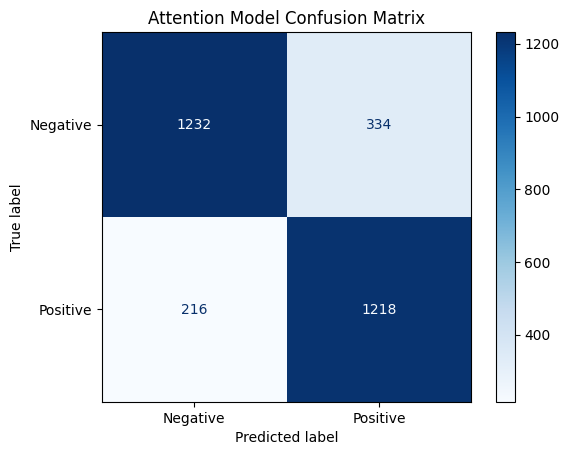

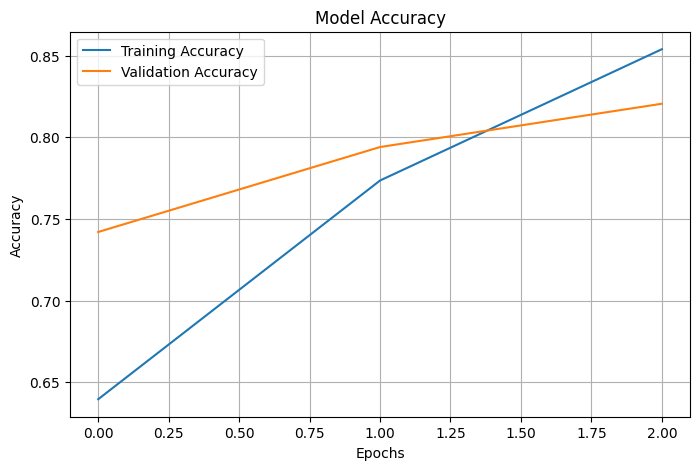

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'attention_layer' (of type AttentionLayer) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


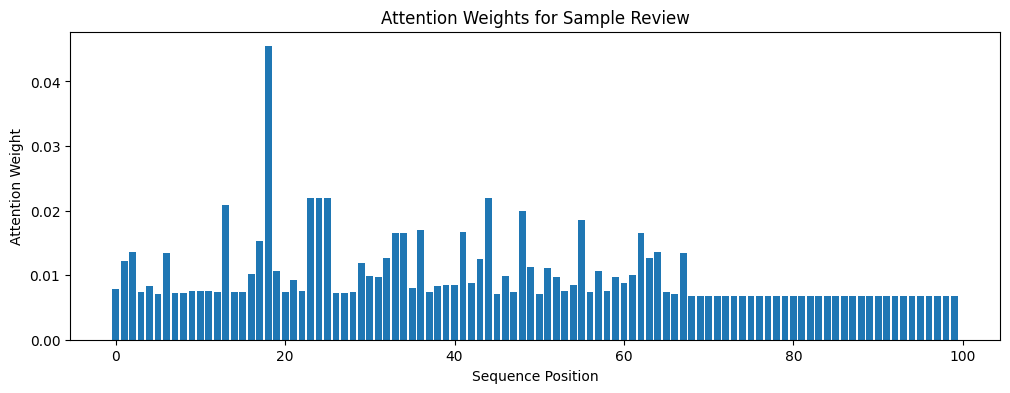


CUSTOM REVIEW PREDICTION
Review: This movie was amazing and wonderful I really enjoyed it
Positive Probability: 0.9933
Sentiment: Positive

Attention Mechanism Implemented Successfully!


In [11]:

# Implementing Attention Mechanism (Basic Custom Model)

!pip install -q tensorflow matplotlib scikit-learn

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, Dense, GlobalAveragePooling1D, Layer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.datasets import imdb
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Load IMDB dataset
vocab_size = 10000
max_length = 100

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

# Use a smaller subset for faster execution
X_train, y_train = X_train[:10000], y_train[:10000]
X_test, y_test = X_test[:3000], y_test[:3000]

# Pad sequences
X_train = pad_sequences(X_train, maxlen=max_length, padding='post', truncating='post')
X_test = pad_sequences(X_test, maxlen=max_length, padding='post', truncating='post')

# Custom Attention Layer
class AttentionLayer(Layer):
    def __init__(self, **kwargs):
        super(AttentionLayer, self).__init__(**kwargs)

    def build(self, input_shape):
        self.W = self.add_weight(
            name='attention_weight',
            shape=(input_shape[-1], 1),
            initializer='glorot_uniform',
            trainable=True
        )
        self.b = self.add_weight(
            name='attention_bias',
            shape=(1,),
            initializer='zeros',
            trainable=True
        )
        super().build(input_shape)

    def call(self, inputs):
        scores = tf.nn.tanh(tf.matmul(inputs, self.W) + self.b)
        weights = tf.nn.softmax(scores, axis=1)
        context_vector = tf.reduce_sum(inputs * weights, axis=1)
        return context_vector, weights

# Build custom attention model
inputs = Input(shape=(max_length,))

embedding = Embedding(
    input_dim=vocab_size,
    output_dim=64,
    mask_zero=True
)(inputs)

attention_output, attention_weights = AttentionLayer()(embedding)

dense = Dense(32, activation='relu')(attention_output)
outputs = Dense(1, activation='sigmoid')(dense)

model = Model(inputs=inputs, outputs=outputs)

# Compile model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

# Train model
history = model.fit(
    X_train,
    y_train,
    epochs=3,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

# Evaluate model
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

print("\nMODEL EVALUATION")
print("Test Loss:", round(loss, 4))
print("Test Accuracy:", round(accuracy * 100, 2), "%")

# Predictions
predictions = model.predict(X_test, verbose=0).flatten()
predicted_labels = (predictions >= 0.5).astype(int)

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    predicted_labels,
    target_names=['Negative', 'Positive']
))

# Confusion matrix
cm = confusion_matrix(y_test, predicted_labels)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Negative', 'Positive']
).plot(cmap='Blues')

plt.title("Attention Model Confusion Matrix")
plt.show()

# Accuracy visualization
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

# Create attention visualization model
attention_model = Model(
    inputs=inputs,
    outputs=AttentionLayerOutput if False else model.layers[2].output
)

# Extract attention weights from the trained layer
attention_layer = next(
    layer for layer in model.layers
    if isinstance(layer, AttentionLayer)
)

attention_extractor = Model(
    inputs=model.input,
    outputs=attention_layer.output[1]
)

sample = X_test[0:1]
weights = attention_extractor.predict(sample, verbose=0)[0].flatten()

# Visualize attention weights
plt.figure(figsize=(12, 4))
plt.bar(range(max_length), weights)
plt.title("Attention Weights for Sample Review")
plt.xlabel("Sequence Position")
plt.ylabel("Attention Weight")
plt.show()

# Custom review prediction
word_index = imdb.get_word_index()

def encode_review(text):
    sequence = [
        word_index.get(word, 2) + 3
        for word in text.lower().split()
    ]
    return pad_sequences(
        [sequence],
        maxlen=max_length,
        padding='post',
        truncating='post'
    )

custom_review = "This movie was amazing and wonderful I really enjoyed it"

custom_sequence = encode_review(custom_review)
prediction = model.predict(custom_sequence, verbose=0)[0][0]

print("\nCUSTOM REVIEW PREDICTION")
print("Review:", custom_review)
print("Positive Probability:", round(float(prediction), 4))
print("Sentiment:", "Positive" if prediction >= 0.5 else "Negative")

print("\nAttention Mechanism Implemented Successfully!")
